# **AAPL Stock Performance Analysis**

# Introduction

**Company:** Apple Inc.   
**Ticker Symbol:** AAPL  
**Data Period:** September 29, 2025 to September 25, 2026 (approximately one year of daily trading data)   
**Data Source:** Yahoo Finance (finance.yahoo.com)

The dataset includes daily Open, High, Low, Close, Adjusted Close and Volume figures for Apple Inc., obtained via Yahoo Finance. This analysis uses the daily Closing Price and Volume columns as the primary basis for the descriptive statistics, trend analysis and event investigation that follow. I used the Close column rather than Adj Close because the goal is to describe the price investors actually saw each day.

# Part 1: Data Setup

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

#Load the AAPL data directly from GitHub
url = "https://raw.githubusercontent.com/ranxinjiang/AAPL-Stock-Performance-Analysis/refs/heads/main/AAPL.csv"
df = pd.read_csv(url)

#Convert the Date column to datetime type
df['Date'] = pd.to_datetime(df['Date'])

#Sort by date just in case, and reset the row numbers to 0, 1, 2, etc.
df = df.sort_values('Date').reset_index(drop=True)

#Confirm the data period and number of observations
print(f"Data Period: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"Number of Trading days: {len(df)}")

df.head()

Data Period: 2025-09-29 to 2026-09-25
Number of Trading days: 250


,Date,Open,High,Low,Close,Adj Close,Volume
0,2025-09-29,254.559998,255.000000,253.009995,254.429993,253.493607,40127700
1,2025-09-30,254.860001,255.919998,253.110001,254.630005,253.692871,37704300
2,2025-10-01,255.039993,258.790009,254.929993,255.449997,254.509842,48713900
3,2025-10-02,256.579987,258.179993,254.149994,257.130005,256.183655,42630200
4,2025-10-03,254.669998,259.239990,253.949997,258.019989,257.070374,49155600


# Part 2: Descriptive Analytics
### A. Summary Statistics


In [ ]:
price_stats = df['Close'].describe()
print("AAPL Closing Price - Summary Statistics")
print(price_stats)

volume_stats = df['Volume'].describe()
print("\nAAPL Trading Volume - Summary Statistics")
print(volume_stats)

AAPL Closing Price - Summary Statistics
count    250.000000
mean     283.421599
std       26.271383
min      245.270004
25%      260.884987
50%      273.959992
75%      307.082496
max      341.070007
Name: Close, dtype: float64

AAPL Trading Volume - Summary Statistics
count    2.500000e+02
mean     4.830113e+07
std      2.145173e+07
min      1.791060e+07
25%      3.791430e+07
50%      4.457905e+07
75%      5.152402e+07
max      2.617755e+08
Name: Volume, dtype: float64


Over the 250 trading days in the sample, AAPL's closing price averaged \$283.42, with a median of \$273.96. This gap of roughly \$9.50 shows the mean sitting above the median, which means the price distribution is right-skewed. This pattern suggests the stock spent more of the year trading at lower prices, with fewer but higher-priced days pulling the average upward.

The price varied a lot over the year. The closing prices ranged from a low of \$245.27 to a high of \$341.07, a spread of nearly \$96, or about 39% of the minimum price. The standard deviation of \$26.27 backs this up and shows real movement in the stock rather than a tightly range-bound price.

The trading volume averaged about 48.3 million shares per day, with a median of 44.6 million. The volume skews right as well, since the mean sits above the median here too, pointing to a handful of unusually high-volume days pulling the average up. The standard deviation of volume, about 21.5 million, is large relative to its mean and shows trading activity was considerably more variable than price alone would suggest.

### B. Price Movement over Time

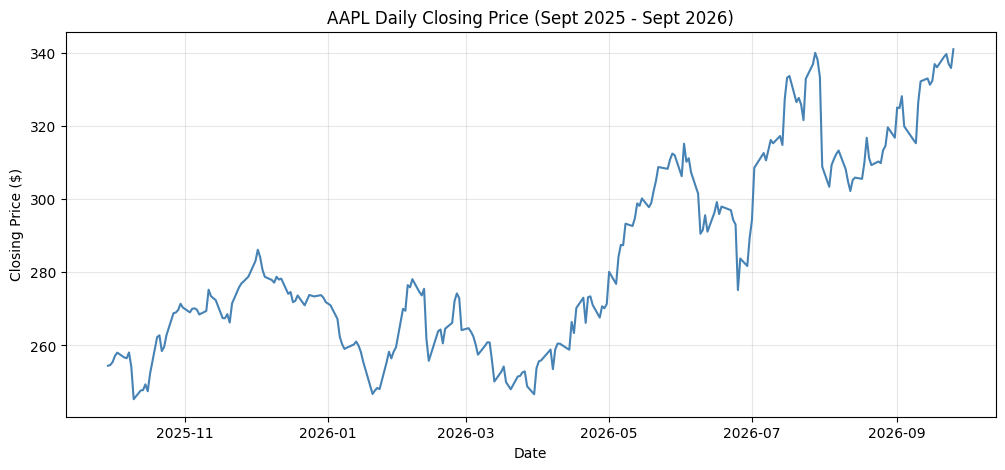

Starting Price: $254.43 on 2025-09-29
Ending Price: $341.07 on 2026-09-25
Overall Change: 34.05%
Largest Single-day Gain: 4.84% on 2026-07-02
Largest Single-day Loss: -7.35% on 2026-07-31


In [ ]:
#Line chart of closing price over the full year
plt.figure(figsize=(12, 5))
plt.plot(df['Date'], df['Close'], color='steelblue')
plt.title('AAPL Daily Closing Price (Sept 2025 - Sept 2026)')
plt.xlabel('Date')
plt.ylabel('Closing Price ($)')
plt.grid(alpha=0.3)
plt.show()

#Calculate overall change and largest single-day moves
start_price = df['Close'].iloc[0]
end_price = df['Close'].iloc[-1]
pct_change = (end_price - start_price) / start_price * 100

#Daily return in percent
df['Daily_Return'] = df['Close'].pct_change() * 100
max_gain_idx = df['Daily_Return'].idxmax()
max_loss_idx = df['Daily_Return'].idxmin()

print(f"Starting Price: ${start_price:.2f} on {df['Date'].iloc[0].date()}")
print(f"Ending Price: ${end_price:.2f} on {df['Date'].iloc[-1].date()}")
print(f"Overall Change: {pct_change:.2f}%")
print(f"Largest Single-day Gain: {df['Daily_Return'].max():.2f}% on {df['Date'][max_gain_idx].date()}")
print(f"Largest Single-day Loss: {df['Daily_Return'].min():.2f}% on {df['Date'][max_loss_idx].date()}")

In [ ]:
#Group the days by month to find the calmest and most volatile periods
df['Month'] = df['Date'].dt.to_period('M')
monthly = df.groupby('Month').agg(Return_Std=('Daily_Return', 'std'),
                                  Low_Close=('Close', 'min'),
                                  High_Close=('Close', 'max'),
                                  Avg_Volume=('Volume', 'mean'))
monthly['Avg_Volume'] = monthly['Avg_Volume'] / 1000000

print("Monthly Volatility and Price Range (Return_Std = std of daily returns in %)")
print("Note: September 2025 only has 2 trading days, so its std is blank")
print(monthly.round(2))
print(f"\nFull-year STD of Daily Returns: {df['Daily_Return'].std():.2f}%")

Monthly Volatility and Price Range (Return_Std = std of daily returns in %)
Note: September 2025 only has 2 trading days, so its std is blank
         Return_Std  Low_Close  High_Close  Avg_Volume
Month                                                 
2025-09         NaN     254.43      254.63       38.92
2025-10        1.44     245.27      271.40       47.70
2025-11        0.96     266.25      278.85       46.19
2025-12        0.75     270.97      286.19       42.02
2026-01        1.27     246.70      271.01       52.00
2026-02        2.20     255.78      278.12       52.05
2026-03        1.19     246.63      264.72       40.91
2026-04        1.48     253.50      273.43       43.22
2026-05        1.10     276.83      312.51       49.06
2026-06        2.20     275.15      315.20       66.72
2026-07        2.45     294.38      340.08       54.49
2026-08        1.19     302.25      319.70       42.97
2026-09        1.42     315.34      341.07       43.22

Full-year STD of Daily Returns: 

The closing price chart shows an overall upward trend for the year. AAPL started at \$254.43 on September 29, 2025 and ended at \$341.07 on September 25, 2026, a gain of about 34%. The rise was not steady, and the chart shows clear swings along the way rather than a smooth climb.

The monthly table splits the year into calmer and rougher stretches. The calmest stretch came in late 2025. The standard deviation of daily returns fell to 0.96% in November and 0.75% in December, and the price stayed between about \$266 and \$286. Early 2026 was weaker, and the price fell back to \$246.70 in January and \$246.63 in March, close to the yearly low of \$245.27 from October 2025. February, June and July 2026 were the most volatile months, with daily return standard deviations of 2.20%, 2.20% and 2.45%, roughly 1.4 to 1.6 times the full-year figure of 1.55%. May 2026 also stands out. The price climbed from a monthly low of \$276.83 to a high of \$312.51, yet volatility stayed low at 1.10%, which points to a steady climb rather than a jumpy one.

Two single-day moves stand out. The largest single-day gain of 4.84% came on July 2, 2026, and the largest single-day loss of 7.35% followed on July 31, 2026, visible as a steep downward spike on the chart. Both fall inside the volatile summer stretch, and Part 3 looks at what happened around each date.

Overall, the chart supports a story of a stock that trended higher over the full period. It moved through a quiet late 2025 and a choppy early 2026, then went through a turbulent summer before finishing at its highest close of the year.

### C. Trading Volume

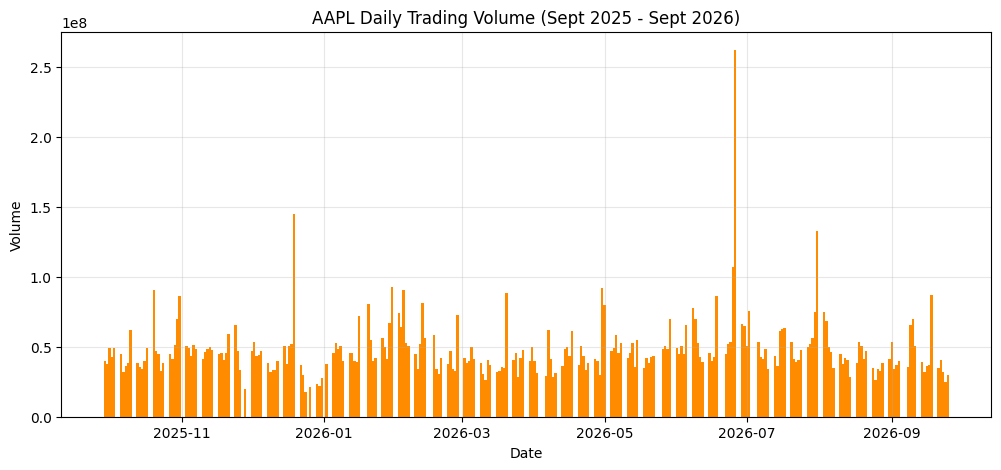

Top 5 Highest-Volume Trading Days:
      Date      Close    Volume  Daily_Return
2026-06-26 283.779999 261775500      3.136473
2025-12-19 273.670013 144632000      0.543742
2026-07-31 308.910004 132489100     -7.353864
2026-06-25 275.149994 107013700     -6.117781
2026-01-30 259.480011  92443400      0.464617


In [ ]:
#Bar chart of trading volume over time
plt.figure(figsize=(12, 5))
plt.bar(df['Date'], df['Volume'], color='darkorange', width=1)
plt.title('AAPL Daily Trading Volume (Sept 2025 - Sept 2026)')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.grid(alpha=0.3)
plt.show()

#Identify the highest-volume trading days and show the same-day price change
top_volume_days = df.sort_values('Volume', ascending=False).head(5)
print("Top 5 Highest-Volume Trading Days:")
print(top_volume_days[['Date', 'Close', 'Volume', 'Daily_Return']].to_string(index=False))

The busiest trading day in the sample was June 26, 2026, with about 261.8 million shares traded and a price gain of about 3.14%. This date lines up with the June Russell index reconstitution, when the Russell indexes update which companies they include after the market close (LSEG, 2026), so much of this volume likely came from funds that track those indexes rather than a reaction to Apple news. The day before, June 25, also ranked in the top five with about 107.0 million shares and a sharp drop of about 6.12%, which Part 3 connects to Apple's Mac and iPad price hikes (Event 1).

The third-highest volume day, July 31, 2026, saw about 132.5 million shares traded alongside a drop of about 7.35%. This came the day after Apple's fiscal Q3 2026 earnings release, which Part 3 covers as Event 3. Here, the unusual volume coincided with a large price move.

The second-highest volume day, December 19, 2025, tells a different story. About 144.6 million shares traded, yet the price barely moved, with a same-day change of only about 0.54%. This date was a "triple witching" day, when stock options, index options and index futures all expire on the same day and drive heavy trading across the whole market (Axios, 2025). This contrast shows that high volume does not always signal a big price reaction. Some volume spikes trace back to company-specific news, while others come from routine market mechanics.

### D. Moving Averages


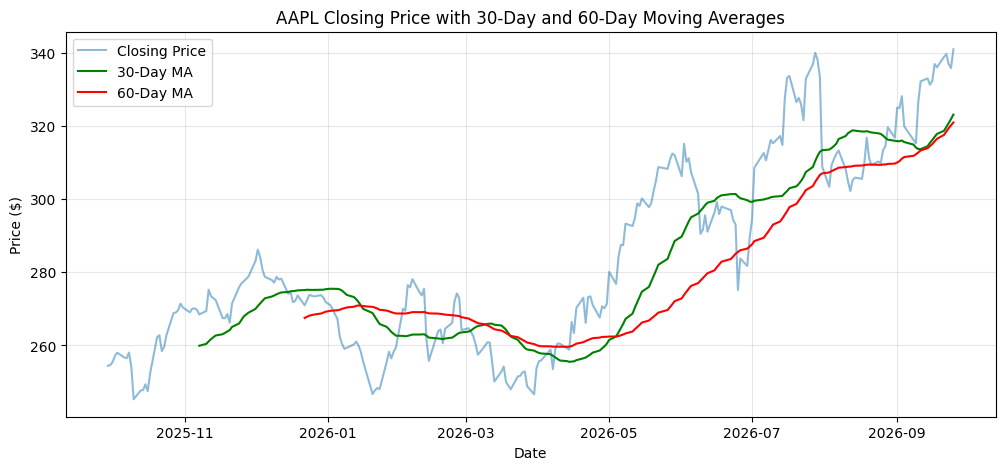

Points Where the 30-day MA Crosses the 60-day MA:
      Date      Close       MA30       MA60
2026-01-16 255.529999 269.988997 270.745166
2026-03-10 260.829987 265.877000 265.479998
2026-03-20 247.990005 262.419333 262.595499
2026-05-04 276.829987 262.447333 262.433333


In [ ]:
#30-day Moving Average
df['MA30'] = df['Close'].rolling(window=30).mean()

#60-day Moving Average
df['MA60'] = df['Close'].rolling(window=60).mean()

#Graph both moving averages
plt.figure(figsize=(12, 5))
plt.plot(df['Date'], df['Close'], label='Closing Price', alpha=0.5)
plt.plot(df['Date'], df['MA30'], label='30-Day MA', color='green')
plt.plot(df['Date'], df['MA60'], label='60-Day MA', color='red')
plt.title('AAPL Closing Price with 30-Day and 60-Day Moving Averages')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#Identify points where the 30-day MA crosses the 60-day MA
df['Sign'] = (df['MA30'] > df['MA60']).astype(int)
df['Sign_Change'] = df['Sign'].diff()
crossovers = df[df['Sign_Change'] != 0].dropna(subset=['MA30', 'MA60'])
crossovers = crossovers.iloc[1:]

print("Points Where the 30-day MA Crosses the 60-day MA:")
print(crossovers[['Date', 'Close', 'MA30', 'MA60']].to_string(index=False))

The moving averages smooth out day-to-day noise and make the underlying trend easier to read than the raw closing price line alone. The chart shows four points where the 30-day average crosses the 60-day average, and each one marks a shift in the shorter-term trend relative to the longer-term one.

The 30-day average first dropped below the 60-day average on January 16, 2026, with the price at \$255.53, signaling a period of short-term weakness. It crossed back above on March 10, 2026 at \$260.83, then dropped below again just ten days later on March 20, 2026 at \$247.99. This back-and-forth pattern in a short window points to a choppy, indecisive stretch in early 2026 where the stock lacked a clear direction, something that is hard to see from the daily price line alone since day-to-day price swings can hide a lack of sustained trend.

The 30-day average crossed back above the 60-day average on May 4, 2026 at \$276.83 and did not cross below again for the rest of the sample period. This signals the start of a more sustained upward trend, consistent with the overall 34% gain in price over the full year. The daily closing price chart shows constant small movements up and down, but the moving averages filter that noise out and make it clear that the stock shifted from a choppy, uncertain period into a more consistent uptrend starting in the spring.

# Part 3: Investigate Important Events

For each event, the code below compares the 5 trading days before the event day with the 5 trading days after it. The event day itself is shown on its own row so it does not get mixed into either average.

In [ ]:
#Event dates (the first trading day each piece of news could affect)
events = {'Event 1: Price Hikes': '2026-06-25',
          'Event 2: iPhone Report': '2026-07-02',
          'Event 3: Q3 Earnings': '2026-07-31'}

rows = []
for name, date in events.items():
    i = df.index[df['Date'] == date][0]     #row number of the event day
    before = df.iloc[i-5:i]                 #5 trading days before the event
    after = df.iloc[i+1:i+6]                #5 trading days after the event

    rows.append({
        'Event': name,
        'Prior Close ($)': df['Close'][i-1],
        'Event Day Close ($)': df['Close'][i],
        'Event Day Change (%)': df['Daily_Return'][i],
        'Event Day Volume (M)': df['Volume'][i] / 1000000,
        'Avg Close 5 Days Before ($)': before['Close'].mean(),
        'Avg Close 5 Days After ($)': after['Close'].mean(),
        'Change in Avg Close (%)': (after['Close'].mean() / before['Close'].mean() - 1) * 100,
        'Avg Volume 5 Days Before (M)': before['Volume'].mean() / 1000000,
        'Avg Volume 5 Days After (M)': after['Volume'].mean() / 1000000,
        'Close 5 Days Later vs Prior Close (%)': (df['Close'][i+5] / df['Close'][i-1] - 1) * 100
    })

event_table = pd.DataFrame(rows).set_index('Event')
print("Part 3 Event Table: 5 Trading Days Before vs. After Each Event")
print(event_table.T.round(2).to_string())

Part 3 Event Table: 5 Trading Days Before vs. After Each Event
Event                                  Event 1: Price Hikes  Event 2: iPhone Report  Event 3: Q3 Earnings
Prior Close ($)                                      293.08                  294.38                333.43
Event Day Close ($)                                  275.15                  308.63                308.91
Event Day Change (%)                                  -6.12                    4.84                 -7.35
Event Day Volume (M)                                 107.01                   75.35                132.49
Avg Close 5 Days Before ($)                          295.67                  284.88                336.33
Avg Close 5 Days After ($)                           291.58                  313.65                309.91
Change in Avg Close (%)                               -1.38                   10.10                 -7.85
Avg Volume 5 Days Before (M)                          55.74                  110.10      

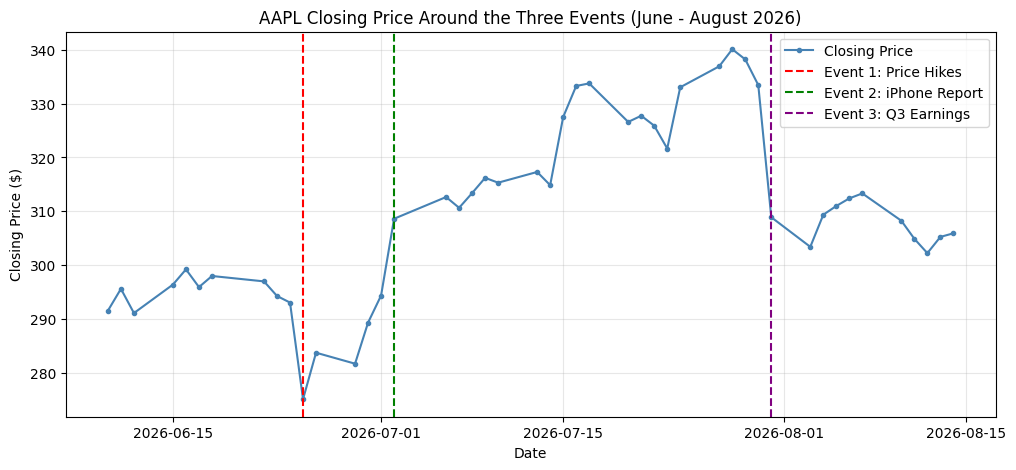

In [ ]:
#Zoomed chart of the price from mid-June to mid-August with the three events marked
zoom = df[(df['Date'] >= '2026-06-10') & (df['Date'] <= '2026-08-14')]

plt.figure(figsize=(12, 5))
plt.plot(zoom['Date'], zoom['Close'], color='steelblue', marker='o', markersize=3, label='Closing Price')
colors = ['red', 'green', 'purple']
for (name, date), c in zip(events.items(), colors):
    plt.axvline(pd.to_datetime(date), color=c, linestyle='--', label=name)
plt.title('AAPL Closing Price Around the Three Events (June - August 2026)')
plt.xlabel('Date')
plt.ylabel('Closing Price ($)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Event 1: Mac and iPad Price Hikes (June 25, 2026)

On June 25, 2026, Apple raised prices on its MacBooks, iPads and some home devices to offset rising memory chip costs (CNBC, 2026a). The investors reacted right away. The top-volume table in Part 2C shows the stock falling 6.12% that day on 107.0 million shares, and the Part 3 event table confirms the drop took the price from \$293.08 to \$275.15. Compared to the 55.7 million shares a day in the five days before, volume nearly doubled. The rest of the Part 3 event table tells a more mixed story for the week after. The average close slipped only 1.38%, from \$295.67 to \$291.58, and five trading days later the stock closed 5.31% above its pre-event price. Volume stayed high at 103.8 million shares a day, but most of this came from June 26, which appears in Part 2C as the busiest day of the year at 261.8 million shares and shows up as the tallest bar on the volume chart. This date lines up with the June Russell index reconstitution, when the Russell indexes update which companies they include after the market close (LSEG, 2026). Overall, the evidence fits a strong one-day reaction to the price hikes, but the quick recovery visible on the Part 3 zoomed chart, which overlaps with Event 2, suggests the news did not lead to a lasting change in price.


### Event 2: New iPhone Lineup Report (July 2, 2026)

Late on July 1, U.S. time, Nikkei Asia reported that Apple planned to launch at least five new iPhone models through early 2027 and had raised its production target for its first foldable iPhone to about 10 million units (Nikkei Asia, 2026; CNBC, 2026b). In Part 2B, we can see that July 2, the first full trading day after the report, brought the largest one-day gain of the year at 4.84%. The Part 3 event table shows the price climbing from \$294.38 to \$308.63 on 75.4 million shares, well above the full-year average of 48.3 million from the Part 2A summary statistics. The gain held up over the following week as well. The Part 3 event table shows the average close rising 10.10%, from \$284.88 in the five days before to \$313.65 in the five days after, with the stock sitting 7.11% above its pre-event price five trading days later. Volume moved in the opposite direction, falling from 110.1 million shares a day to 43.9 million. These numbers fit investors reacting well to the iPhone news, but the comparison has a weak spot. The five days before this event include the June
25 drop and the June 26 rebalance, which drag down the average price and push up the average volume, so both the price gain and the volume decline look bigger than this event alone would explain. Some of the rebound could also come from buyers stepping back in after the June 25 selloff, and the data cannot separate the two.



### Event 3: Q3 Fiscal 2026 Earnings (July 31, 2026)

Apple reported its fiscal Q3 2026 results after the market closed on July 30, 2026. Revenue grew 16% to \$109.42 billion and beat expectations, but the company gave a weak forecast for the next quarter and warned that supply constraints would increase significantly (CNBC, 2026c). Investors got their first full chance to trade on the news on July 31. In Part 2B, we can see this date as the largest one-day loss of the year at 7.35%, and the Part 2C top-volume table shows 132.5 million shares trading hands that day. The Part 3 event table adds that the price fell from \$333.43 to \$308.91 and that volume more than doubled from an average of 56.0 million shares in the five days before. Unlike the June 25 drop, this one stuck. The Part 3 event table shows the average close falling 7.85%, from \$336.33 to \$309.91, with the stock still 6.03% below its pre-event price five trading days later, even as volume settled back to 54.6 million shares a day. The Part 3 zoomed chart makes the
difference easy to see, since the price stays low after July 31 instead of bouncing back. Out of the three events, this one shows the strongest link between company news and a lasting price change, since the drop came right after the report, arrived on heavy volume and held for a full week without overlapping another event. Even so, the numbers show when and how much the stock moved, not why, so the weak forecast stands as the most reasonable
explanation rather than a proven cause.

# Part 4: Develop a 30-Day Price Range

In [ ]:
#Part 4, Code Cell 1
#Evidence 1: Daily volatility (standard deviation of daily returns) over different periods
daily_returns = df['Close'].pct_change()
print(f"Daily volatility, full year: {daily_returns.std()*100:.2f}%")
print(f"Daily volatility, last 60 days: {daily_returns.tail(60).std()*100:.2f}%")
print(f"Daily volatility, last 30 days: {daily_returns.tail(30).std()*100:.2f}%")

#Evidence 3: Where the stock sits now compared to its moving averages
last_price = df['Close'].iloc[-1]
print(f"\nLast closing price: ${last_price:.2f}")
print(f"30-day moving average: ${df['MA30'].iloc[-1]:.2f}")
print(f"60-day moving average: ${df['MA60'].iloc[-1]:.2f}")

Daily volatility, full year: 1.55%
Daily volatility, last 60 days: 1.78%
Daily volatility, last 30 days: 1.30%

Last closing price: $341.07
30-day moving average: $323.17
60-day moving average: $321.02


In [ ]:
#Part 4, Code Cell 2
#30 calendar days is 21 trading days once weekends are removed
trading_days = 21

#Scale daily volatility up to a 21-day move using the square root of time
vol_21 = daily_returns.std() * (trading_days ** 0.5)

lower_bound = last_price * (1 - vol_21)
upper_bound = last_price * (1 + vol_21)

print(f"Expected 21-day move (1 standard deviation): {vol_21*100:.2f}%")
print(f"Estimated 30-day range: ${lower_bound:.2f} to ${upper_bound:.2f}")

Expected 21-day move (1 standard deviation): 7.09%
Estimated 30-day range: $316.87 to $365.27


In [ ]:
#Part 4, Code Cell 3
#Evidence 2: How much did the stock actually move over every 21-trading-day stretch this year?
move_21 = df['Close'].shift(-21) / df['Close'] - 1

print(f"Number of 21-day stretches: {move_21.count()}")
print(f"10th percentile move: {move_21.quantile(0.10)*100:.2f}%")
print(f"Median move: {move_21.median()*100:.2f}%")
print(f"90th percentile move: {move_21.quantile(0.90)*100:.2f}%")

#How many past stretches would have landed inside the range?
inside = ((move_21 >= -vol_21) & (move_21 <= vol_21)).sum()
below = (move_21 < -vol_21).sum()
above = (move_21 > vol_21).sum()
print(f"\nStretches inside the range: {inside} ({inside / move_21.count()*100:.1f}%)")
print(f"Stretches below the range: {below}")
print(f"Stretches above the range: {above}")

Number of 21-day stretches: 229
10th percentile move: -6.64%
Median move: 2.57%
90th percentile move: 11.70%

Stretches inside the range: 147 (64.2%)
Stretches below the range: 16
Stretches above the range: 66


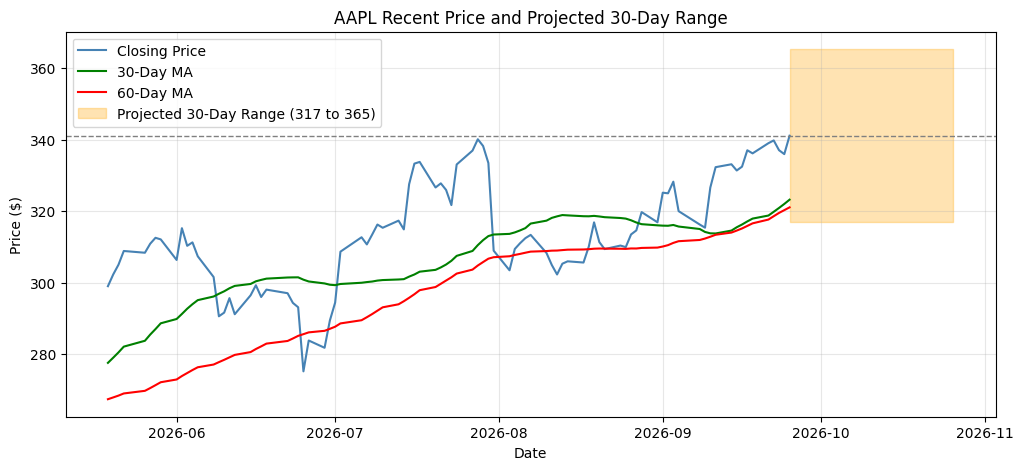

In [ ]:
#Part 4, Code Cell 4
#Plot the last 90 trading days with the projected range shaded for the next 21 trading days
recent = df.tail(90)
future_dates = pd.bdate_range(df['Date'].iloc[-1], periods=trading_days + 1)

plt.figure(figsize=(12, 5))
plt.plot(recent['Date'], recent['Close'], label='Closing Price', color='steelblue')
plt.plot(recent['Date'], recent['MA30'], label='30-Day MA', color='green')
plt.plot(recent['Date'], recent['MA60'], label='60-Day MA', color='red')
plt.fill_between(future_dates, lower_bound, upper_bound, color='orange', alpha=0.3,
                 label=f'Projected 30-Day Range ({lower_bound:.0f} to {upper_bound:.0f})')
plt.axhline(last_price, color='gray', linestyle='--', linewidth=1)
plt.title('AAPL Recent Price and Projected 30-Day Range')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.legend(loc='upper left')
plt.grid(alpha=0.3)
plt.show()

Based on the evidence below, I estimate that AAPL will trade between about \$317 and \$365 over the next 30 days. I centered the range on the last closing price of \$341.07 from Code Cell 1, which the Part 2A summary statistics also show as the highest close of the entire
year.

The first piece of evidence is volatility. Code Cell 1 shows daily volatility of 1.55% for the full year, 1.78% for the last 60 days and 1.30% for the last 30 days. The 60-day number runs higher because it includes both the July 2 jump and the July 31 earnings drop from Part 3, while the 30-day number reflects a calmer stretch from mid-August through September. I used the full-year figure of 1.55% as a middle ground between the two. Since 30 calendar days covers about 21 trading days, Code Cell 2 scales this daily figure up to a 21-day move of 7.09%, which gives a range of \$316.87 to \$365.27.

The second piece of evidence comes from the stock's actual behavior. Code Cell 3 looks at all 229 stretches of 21 trading days in the sample. The typical stretch moved up 2.57%,
while the 10th and 90th percentiles came in at -6.64% and +11.70%. Out of those 229 stretches, 64.2% would have landed inside my range, which comes close to the roughly 68% a one-standard-deviation range should capture. The misses leaned heavily toward the upside, with 66 stretches finishing above the range and only 16 finishing below it. This lopsided split matches the upward trend from Part 2B and suggests my range may play it safe on the upside.

The moving averages add a third check. Code Cell 1 shows the stock trading well above both its 30-day average of \$323.17 and its 60-day average of \$321.02, and the Part 4 chart shows
both lines still rising. The lower bound of \$317 sits just below both averages, so reaching it would mean the stock falls back through them. The Part 3 zoomed chart shows this kind of drop happening after July 31, so it stands as a real possibility rather than an extreme case.

This range rests on a few assumptions. It assumes the next 30 days will look statistically similar to the past year, with volatility near 1.55% a day. It also assumes no built-in
upward or downward drift, which is why the range sits evenly around the current price even though the typical 21-day move was positive. Finally, the square-root-of-time method assumes
daily returns follow a roughly normal, bell-shaped pattern.

The projection also has real limits. First, it cannot predict news. The three events in Part 3 moved the stock between 4.84% and 7.35% in a single day, so one earnings report or
product announcement could use up most of the range in one session. Second, stock returns do not follow a perfect bell curve. The July 31 drop of 7.35% equals about 4.7 times the
average daily volatility, a move a normal distribution would almost never produce, so the real risk of a large swing runs higher than the range suggests. Third, the range comes from
only one year of data during a strong uptrend, and a one-standard-deviation range still leaves about a one-in-three chance that the price ends up outside it.

## References

Axios. (2025, December 19). *When "triple witching" day comes to the market.* https://www.axios.com/2025/12/19/stock-market-triple-witching

CNBC. (2026a, June 25). *Apple stock gets slammed on bigger Mac, iPad price hikes. Why it can weather the storm.* https://www.cnbc.com/2026/06/25/apple-stock-gets-slammed-on-bigger-mac-ipad-price-hikes-why-it-can-weather-the-storm.html

CNBC. (2026b, July 2). *Apple plans five new iPhones through 2027, eyes Chinese-made chips amid foldable push, reports say.* https://www.cnbc.com/2026/07/02/apple-foldable-iphone-production-memory-shortage-china-chipmakers-cxmt-ymtc.html

CNBC. (2026c, July 30). *Apple earnings takeaways: Weak forecast, supply concerns overshadow sales beat in Cook's last report as CEO.* https://www.cnbc.com/2026/07/30/apple-earnings-live-updates.html

LSEG. (2026). *Russell reconstitution.* https://www.lseg.com/en/ftse-russell/russell-reconstitution

Nikkei Asia. (2026, July 2). *Apple to launch 5 new iPhone models to gain market share amid memory crunch.* https://asia.nikkei.com/business/technology/apple-to-launch-5-new-iphone-models-to-gain-market-share-amid-memory-crunch

Yahoo Finance. (2026). *Apple Inc. (AAPL) historical data* [Data set]. Retrieved September 27, 2026, from https://finance.yahoo.com/quote/AAPL/history/